# Phase I · 02 · How does the baseline CNN behave?

We change an image and look at the CNN's output: does it still call the image REAL or FAKE?
The same **10,000 validation images** go through JPEG compression, blur, resizing and noise.
The weights and the 0.5 threshold stay fixed.

This notebook reads the saved predictions and 27 preview images. We do not need to load
the network just to plot its answers. Training is in `baseline_training.ipynb`;
notebook `04` contains the optional recipe for running both models on the edited images again.


## 1. Imports

    Use the project's Python environment. We need NumPy, Matplotlib, Pillow and IPython;
    the optional explorer also uses ipywidgets. Run the cells in order.


In [1]:
# These are the packages we use for arrays, images and plots.
from pathlib import Path
from io import BytesIO
import base64
import csv
import hashlib
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
# Some plots span two cells. Show them only when we call plt.show().
plt.ioff();


## 2. Paths and saved results

The scores and preview images are stored inside this notebook.


In [2]:
# Find the repository even if Jupyter was opened from the phase1 folder.
ROOT = Path.cwd().resolve()
while not (ROOT / "team-info.json").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Open this notebook from inside the Kandy repository.")
    ROOT = ROOT.parent

NOTEBOOK_PATH = ROOT / "phase1" / "02_cnn_behaviour.ipynb"
DATA_DIR = ROOT / "data" / "baseline_seed1"
SAVE_FIGURES = False


In [3]:
# A small helper for readable tables below the plots.
def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


In [4]:
# Read the saved results from this notebook's metadata.
saved_notebook = json.loads(NOTEBOOK_PATH.read_text())
saved = saved_notebook["metadata"]["cifake"]
raw = base64.b64decode(saved["baseline_validation_bundle"], validate=True)
expected_hash = "c57176388e6d839f96c1fa443fd1b09079e9c2b72085b1ee8bd978fa1e8046bd"
assert hashlib.sha256(raw).hexdigest() == expected_hash

with np.load(BytesIO(raw), allow_pickle=False) as archive:
    behavior_arrays = {name: archive[name] for name in archive.files}
behavior_report = saved["baseline_validation_report"]
behavior_scores = behavior_arrays["p_fake"]
behavior_labels = behavior_arrays["labels"]
behavior_conditions_list = behavior_report["conditions"]

# One row per condition, one column per validation image.
assert behavior_scores.shape == (17, 10_000)
assert np.isfinite(behavior_scores).all()
assert ((behavior_scores >= 0) & (behavior_scores <= 1)).all()


In [5]:
# The four strengths are the same as in the original experiment.
PROBE_SEED = 2026
PROBE_FAMILIES = {
    "JPEG": {
        "values": [95, 80, 60, 40],
        "axis": "JPEG quality",
        "labels": ["q95", "q80", "q60", "q40"],
    },
    "Blur": {
        "values": [0.3, 0.6, 1.0, 1.5],
        "axis": "Blur standard deviation (pixels)",
        "labels": ["0.3 px", "0.6 px", "1.0 px", "1.5 px"],
    },
    "Resize": {
        "values": [28, 24, 20, 16],
        "axis": "Intermediate image width (pixels)",
        "labels": ["28 px", "24 px", "20 px", "16 px"],
    },
    "Noise": {
        "values": [0.01, 0.03, 0.05, 0.10],
        "axis": "Noise standard deviation (RGB in [0, 1])",
        "labels": ["0.01", "0.03", "0.05", "0.10"],
    },
}


In [6]:
# Group the original and four edited conditions for each line in a plot.
behavior_groups = {}
for family in PROBE_FAMILIES:
    edited = [i for i, condition in enumerate(behavior_conditions_list)
              if condition["family"] == family]
    behavior_groups[family] = [0] + edited

# The preview dictionary lets us find an image by its validation index.
behavior_previews = dict(zip(
    behavior_arrays["preview_indices"], behavior_arrays["preview_images"]
))
behavior_colors = {"REAL": "#0072B2", "FAKE": "#D55E00"}
RUN_NAME = "baseline_plain_seed1"


## 3. Turn scores into rates

    P(FAKE) above 0.5 means FAKE. We calculate missed fakes and false alarms separately,
    because accuracy alone can hide a shift toward one label.


In [7]:
# Work on saved outputs only; the model stays fixed.
def behavior_metrics(probabilities, labels):
    """Summarize saved FAKE probabilities without changing the classification threshold."""
    truth_fake = labels == 0
    predicted_fake = probabilities > 0.5  # A tie is REAL, matching the baseline.
    correct = predicted_fake == truth_fake[None, :]
    # Compare every edited prediction with the same image before editing.
    clean_correct = correct[0]
    return {
        "accuracy": correct.mean(axis=1),
        "fake_detected": predicted_fake[:, truth_fake].mean(axis=1),
        "real_accepted": (~predicted_fake[:, ~truth_fake]).mean(axis=1),
        "real_false_alarm": predicted_fake[:, ~truth_fake].mean(axis=1),
        "changed_label": (predicted_fake != predicted_fake[0]).mean(axis=1),
        "new_mistake": (clean_correct[None, :] & ~correct).mean(axis=1),
        "corrected_mistake": (~clean_correct[None, :] & correct).mean(axis=1),
    }


In [8]:
behavior_stats = behavior_metrics(behavior_scores, behavior_labels)
# These two values also check that we loaded the expected run.
assert np.isclose(behavior_stats["accuracy"][0], 0.9454)
assert np.isclose(behavior_stats["accuracy"][9], 0.6213)
print(f"Clean accuracy: {behavior_stats['accuracy'][0]:.2%}")
print(f"Fakes detected: {behavior_stats['fake_detected'][0]:.2%}")
print(f"Real photos flagged: {behavior_stats['real_false_alarm'][0]:.2%}")


Clean accuracy: 94.54%
Fakes detected: 94.60%
Real photos flagged: 5.52%


In [9]:
# Show the plot, and optionally save a PNG.
def finish_behavior_figure(fig, filename):
    if SAVE_FIGURES:
        destination = ROOT / "results" / f"{RUN_NAME}_validation_behavior"
        destination.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            destination / f"{filename}.png",
            dpi=160,
            bbox_inches="tight",
            facecolor="white",
        )
    plt.show()
    plt.close(fig)


In [10]:
# Keep the plot style the same throughout.
def behavior_axes_style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.15)
    ax.set_axisbelow(True)


## 4. Inspect a few validation predictions

    If the local validation images are available, we show four random images of each label
    with their saved scores. The split checksum ensures the images match those scores.
    Without the dataset, the saved galleries in section 5 still work.


In [11]:
# Only this extra random gallery needs the full validation images.
have_validation_images = (DATA_DIR / "val_images.npy").exists()
if have_validation_images:
    manifest_hash = hashlib.sha256((DATA_DIR / "manifest.csv").read_bytes()).hexdigest()
    assert manifest_hash == behavior_report["manifest_sha256"]
    val_images = np.load(DATA_DIR / "val_images.npy", mmap_mode="r")
    val_labels = np.load(DATA_DIR / "val_labels.npy")
    assert np.array_equal(val_labels, behavior_labels)
    sample_rng = np.random.default_rng(42)
    sample_indices = np.concatenate([
        sample_rng.choice(np.flatnonzero(val_labels == label), 4, replace=False)
        for label in (0, 1)
    ])
else:
    print("No local validation images. Continue to the bundled galleries below.")


No local validation images. Continue to the bundled galleries below.


In [12]:
# Attach the stored score to each sampled image.
if have_validation_images:
    fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
    for ax, index, probability in zip(axes.flat, sample_indices, behavior_scores[0, sample_indices]):
        truth = "FAKE" if val_labels[index] == 0 else "REAL"
        # Keep the decision threshold fixed for every strength.
        predicted = "FAKE" if probability > 0.5 else "REAL"
        ax.imshow(val_images[index].transpose(1, 2, 0), interpolation="nearest")
        ax.set_title(
            f"True: {truth} · Pred: {predicted}\nP(fake) = {probability:.1%}",
            fontsize=10,
            color="#28734e" if truth == predicted else "#a63434",
        )
        ax.axis("off")
    fig.suptitle("Validation examples · selected checkpoint", fontweight="bold")
    plt.show()


## 5. How does the CNN react when we change the images?

Here we'll use the trained CNN to explore its behaviour under changes to the input. We'll apply JPEG compression, blur, resizing, and noise to the **same 10,000 validation images**, keeping the model weights and the decision threshold fixed. For each type of change, we'll compare four strengths with the untouched original. This lets us follow a particular image as its prediction changes, as well as see whether real and fake images are affected differently across the full validation set.

The recorded probe uses **5,000 FAKE and 5,000 REAL images**, the selected epoch-19 baseline, and a fixed seed of 2026. The original images are the control: they are not re-encoded or resized. All modified inputs remain 32×32 RGB. JPEG quality is 95, 80, 60, or 40 with fixed 4:4:4 chroma sampling; blur standard deviation is 0.3, 0.6, 1.0, or 1.5 pixels; resizing goes from 32 to 28, 24, 20, or 16 pixels and back with bilinear interpolation; Gaussian noise has standard deviation 0.01, 0.03, 0.05, or 0.10 on RGB values in `[0,1]`. Noise is clipped and rounded back to 8-bit pixels, and each image uses the same noise pattern at every strength.

These are exploratory **validation** results. They help us choose what to investigate before the later model comparison; the existing test evaluation is not repeated. The figures and explorer below work from bundled prediction scores and 27 preview images, even without a local dataset. To rerun the models, use the optional rebuild cells in notebook `04`. The plots here always use the bundled epoch-19 predictions.


The next function recreates an edit for the thumbnails. It does not run the model.
    Noise uses the same random pattern at every strength, so only its size changes.


In [13]:
def modify_behavior_image(image, family, value, image_index, seed=PROBE_SEED):
    """Pure pixel transformation: uint8 CHW in/out, always 3x32x32."""
    assert image.dtype == np.uint8 and image.shape == (3, 32, 32)
    if family == "Original":
        return image.copy()
    if family == "Noise":
        # Reuse one noise field per image at every strength and in the explorer.
        rng = np.random.default_rng(np.random.SeedSequence([seed, int(image_index)]))
        noise = rng.standard_normal(image.shape, dtype=np.float32)
        changed = np.clip(image.astype(np.float32) / 255 + float(value) * noise, 0, 1)
        return np.rint(changed * 255).astype(np.uint8)
    # Pillow expects height × width × colour, so move the colour axis last.
    source = Image.fromarray(image.transpose(1, 2, 0))
    if family == "JPEG":
        stream = BytesIO()
        # Keep chroma sampling fixed at 4:4:4; vary quality only.
        source.save(
            stream,
            format="JPEG",
            quality=int(value),
            subsampling=0,
            optimize=False,
            progressive=False,
        )
        stream.seek(0)
        with Image.open(stream) as decoded:
            result = np.array(decoded.convert("RGB"), dtype=np.uint8)
    elif family == "Blur":
        result = np.array(
            source.filter(ImageFilter.GaussianBlur(radius=float(value))), dtype=np.uint8
        )
    elif family == "Resize":
        width = int(value)
        result = np.array(
            source.resize((width, width), resample=Image.Resampling.BILINEAR).resize(
                (32, 32), resample=Image.Resampling.BILINEAR
            ),
            dtype=np.uint8,
        )
    else:
        raise ValueError(f"Unknown modification: {family}")
    return result.transpose(2, 0, 1).copy()


The gallery helper puts the original and four edited versions next to each other. The examples were selected for large score changes.


In [14]:
# Each row follows one image through one kind of edit.
def plot_behavior_gallery(class_name):
    fig, axes = plt.subplots(4, 5, figsize=(12.5, 10.7), layout="constrained")
    for row, family in enumerate(PROBE_FAMILIES):
        # Reuse the recorded example selection, rather than choosing a new image.
        index = behavior_report["gallery_indices"][family][class_name]
        original = behavior_previews[index]
        for column, condition_index in enumerate(behavior_groups[family]):
            condition = behavior_conditions_list[condition_index]
            changed = modify_behavior_image(
                original, condition["family"], condition["value"], index
            )
            # The image edit is redrawn, but its score was measured in the saved run.
            score = float(behavior_scores[condition_index, index])
            # Keep the decision threshold fixed for every strength.
            predicted = "FAKE" if score > 0.5 else "REAL"
            color = "#28734e" if predicted == class_name else "#a63434"
            ax = axes[row, column]
            ax.imshow(changed.transpose(1, 2, 0), interpolation="nearest")
            label = "Original" if column == 0 else condition["label"]
            ax.set_title(
                f"{family} · {label}\nP(fake)={score:.1%} · {predicted}",
                fontsize=9,
                color=color,
            )
            ax.axis("off")
            if column == 0:
                ax.text(
                    0.5,
                    -0.045,
                    Path(str(behavior_arrays["paths"][index])).name,
                    transform=ax.transAxes,
                    ha="center",
                    va="top",
                    fontsize=8,
                )
    fig.suptitle(
        f"True label: {class_name} · selected sensitive validation examples\nGreen title = correct; red title = wrong",
        fontsize=13,
        fontweight="bold",
    )
    finish_behavior_figure(fig, f"gallery_{class_name.lower()}")


### 5.1 Watch the same fake image change

We'll first look at one fake image for each kind of modification, with the original on the left and four changed versions beside it. Each row follows the same image, so differences in its score cannot be explained by switching to a different picture. The title above each thumbnail gives P(FAKE) and the predicted label; green titles are correct and red titles are mistakes. To make sensitivity visible, each example was chosen from images the CNN originally classified correctly, using the largest drop in P(FAKE) at the second tested strength. These are deliberately selected cases rather than a random sample. Look for the point where the prediction changes, how much the image has visibly changed by then, and whether the score continues in the same direction as the modification becomes stronger.


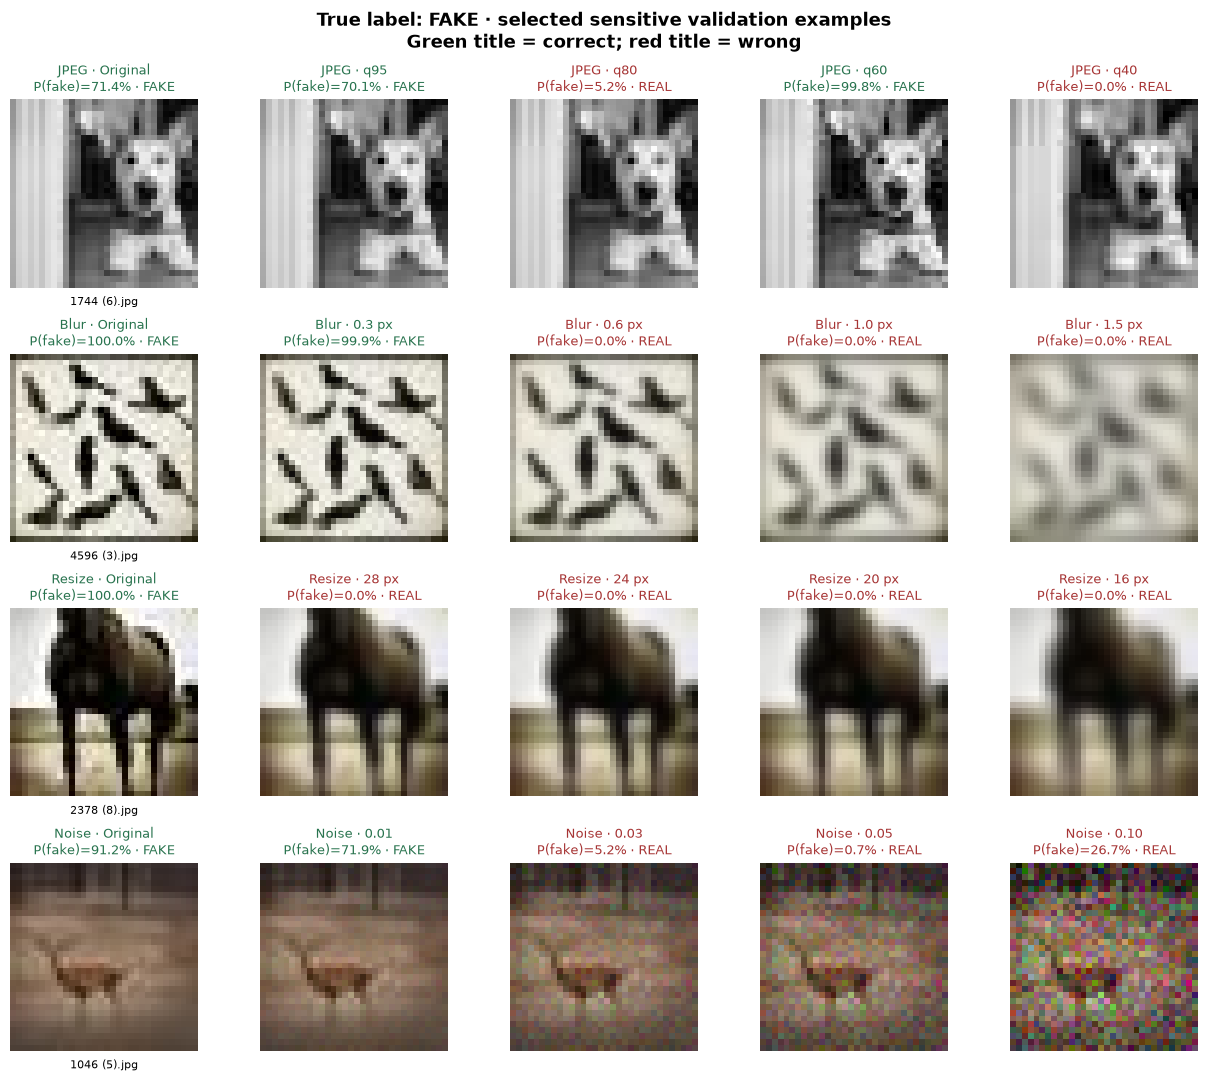

In [15]:
# Show the saved sensitive example for each edit.
if behavior_arrays is not None:
    plot_behavior_gallery("FAKE")


### 5.2 What happens to real images?

The same changes can also cause a different kind of mistake: a real image may start to look fake to the model. We'll use the same layout for real validation images, again showing the original and all four strengths. Here the chosen examples have the largest rise in P(FAKE) at the second tested strength among images that were originally classified correctly. Comparing these rows with the fake-image gallery helps us see whether a modification shifts both classes in the same direction or affects them differently. An example may remain correctly classified even after a large score change, and a stronger modification may sometimes reverse an earlier change. The full-set plots below will show how common these behaviours are.


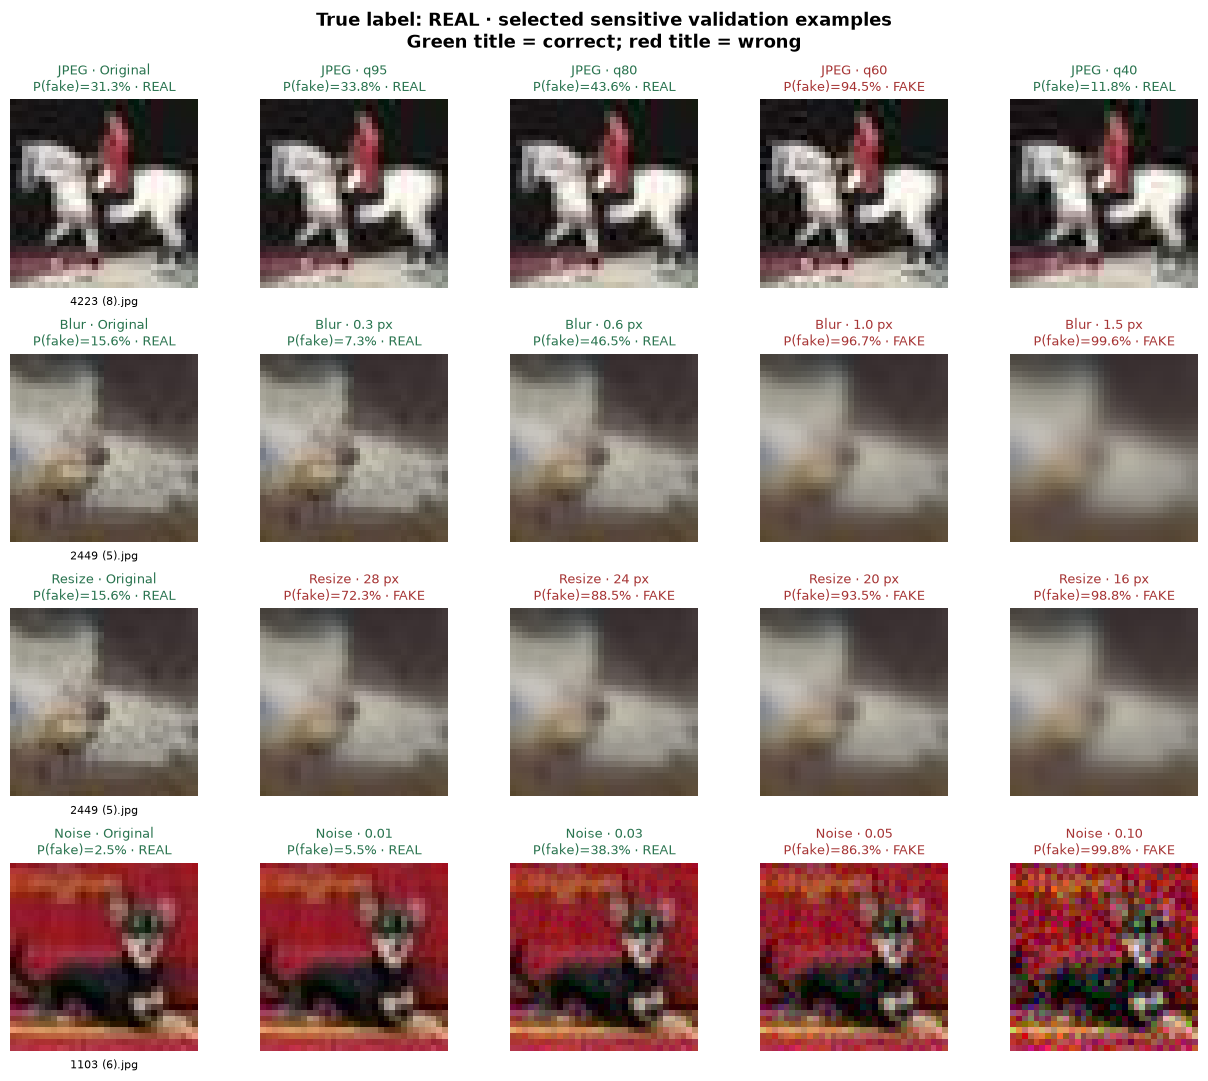

In [16]:
# Show the saved sensitive example for each edit.
if behavior_arrays is not None:
    plot_behavior_gallery("REAL")


### 5.3 Compare behaviour across all validation images

The galleries make individual changes visible, but they were chosen to show sensitivity. We'll now use all 10,000 validation images to put those examples in context. Each panel will plot the original input and the four tested settings for one modification. The orange line shows the percentage of fake images correctly detected, the blue line shows the percentage of real images correctly accepted, and the dashed line shows overall accuracy. All three lines use the same percentage scale. If one class stays accurate while the other drops, the model may be shifting toward one predicted label, which an overall accuracy curve alone would hide. The horizontal settings are specific to each modification; the same position in different panels does not mean an equally strong visual change. Lines connect measured settings and do not represent results for untested strengths.


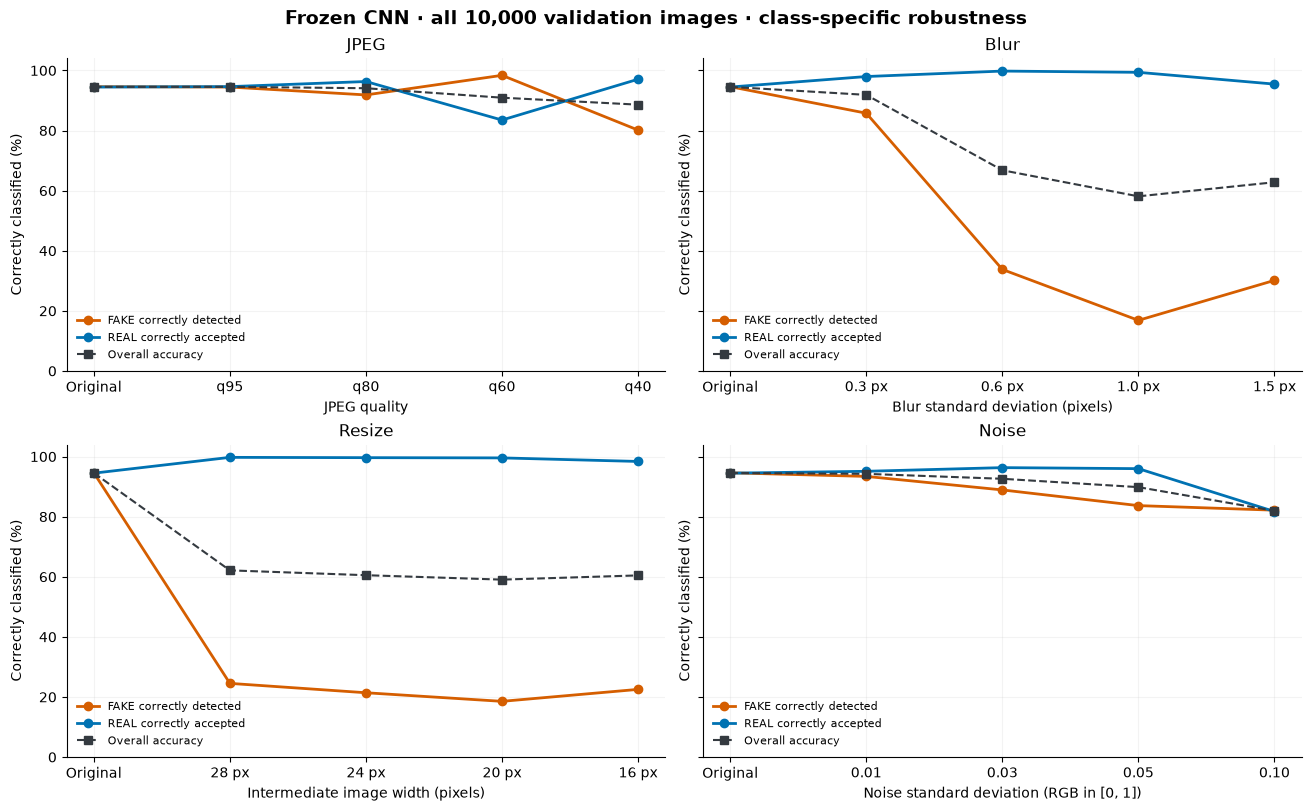

In [17]:
# Calculate rates over all 10,000 images.
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", sharey=True)
for ax, (family, indices) in zip(axes.flat, behavior_groups.items()):
    x = np.arange(len(indices))
    ax.plot(
        x,
        100 * behavior_stats["fake_detected"][indices],
        color=behavior_colors["FAKE"],
        marker="o",
        label="FAKE correctly detected",
        lw=2,
    )
    ax.plot(
        x,
        100 * behavior_stats["real_accepted"][indices],
        color=behavior_colors["REAL"],
        marker="o",
        label="REAL correctly accepted",
        lw=2,
    )
    ax.plot(
        x,
        100 * behavior_stats["accuracy"][indices],
        color="#343a40",
        marker="s",
        ls="--",
        label="Overall accuracy",
        lw=1.5,
    )
    ax.set(
        title=family,
        xlabel=PROBE_FAMILIES[family]["axis"],
        ylabel="Correctly classified (%)",
        ylim=(0, 104),
        xticks=x,
        xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
    )
    behavior_axes_style(ax)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle(
    "Frozen CNN · all 10,000 validation images · class-specific robustness",
    fontsize=14,
    fontweight="bold",
)
finish_behavior_figure(fig, "robustness_curves")


### 5.4 See how the probability scores move

A label only tells us which side of the decision threshold an image falls on. To see the size and direction of the change, we'll plot each image's original P(FAKE) on the horizontal axis and its modified P(FAKE) on the vertical axis. Points on the diagonal have unchanged scores; points below it moved toward REAL and points above it moved toward FAKE. The horizontal and vertical lines at 0.5 divide the plot into regions where predictions stayed the same or switched labels. We'll show the same seeded sample of 400 real and 400 fake validation images in each panel, using the second tested setting for each modification. These settings are labelled explicitly and are not assumed to have equivalent severity. This view makes it possible to distinguish a general shift in scores from a few isolated label changes.


In [18]:
# Use a balanced sample so the scatter stays readable.
score_rng = np.random.default_rng(PROBE_SEED)
behavior_scatter_ids = np.concatenate(
    [
        score_rng.choice(
            np.flatnonzero(behavior_labels == label), 400, replace=False
        )
        for label in [0, 1]
    ]
)


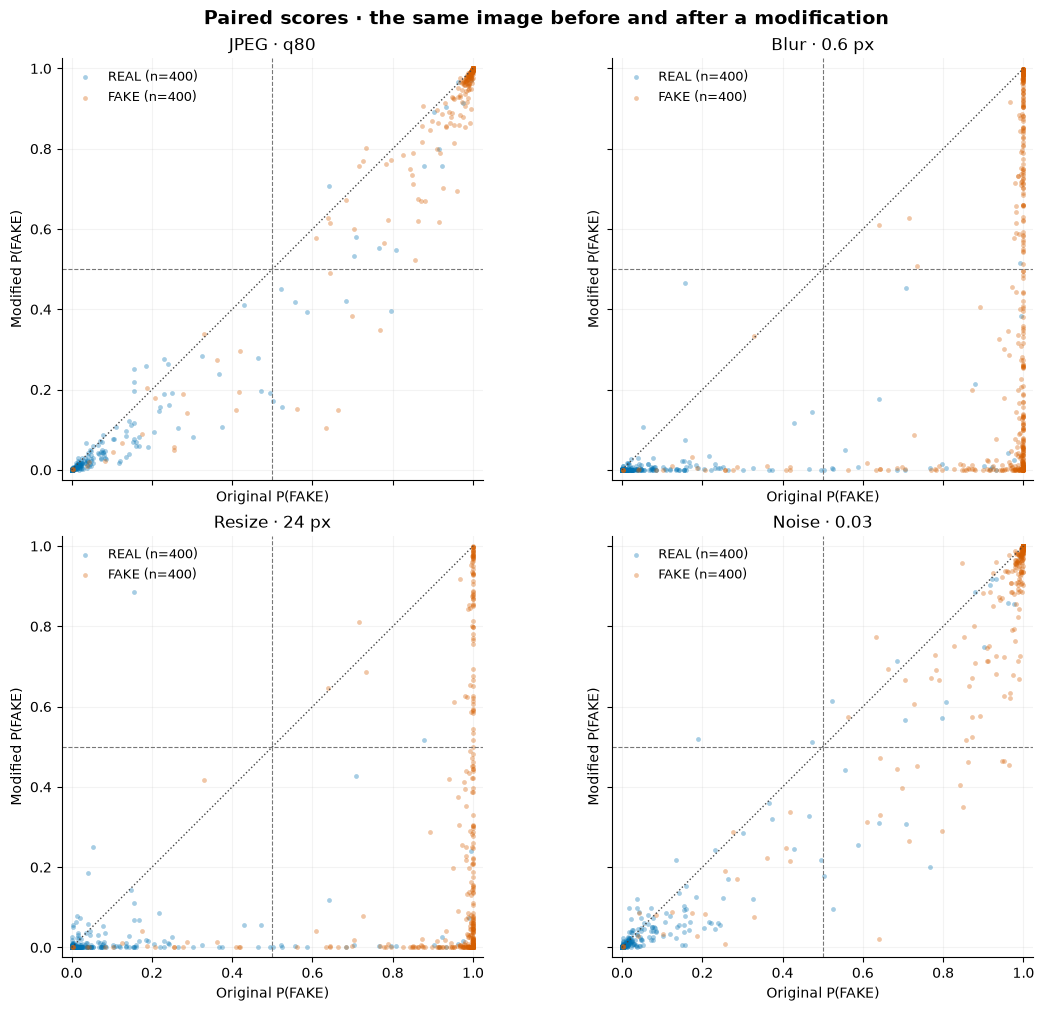

In [19]:
# Plot original versus edited scores for the same sampled images.
fig, axes = plt.subplots(
    2, 2, figsize=(11, 10), layout="constrained", sharex=True, sharey=True
)
for ax, (family, indices) in zip(axes.flat, behavior_groups.items()):
    condition_index = indices[2]
    for name, label in [("REAL", 1), ("FAKE", 0)]:
        ids = behavior_scatter_ids[behavior_labels[behavior_scatter_ids] == label]
        ax.scatter(
            behavior_scores[0, ids],
            behavior_scores[condition_index, ids],
            s=12,
            alpha=0.35,
            color=behavior_colors[name],
            linewidths=0,
            label=f"{name} (n=400)",
        )
    ax.plot([0, 1], [0, 1], ls=":", color="#444444", lw=1)
    ax.axvline(0.5, ls="--", color="#777777", lw=0.8)
    # Crossing this line changes the predicted label.
    ax.axhline(0.5, ls="--", color="#777777", lw=0.8)
    ax.set(
        title=f"{family} · {behavior_conditions_list[condition_index]['label']}",
        xlabel="Original P(FAKE)",
        ylabel="Modified P(FAKE)",
        xlim=(-0.025, 1.025),
        ylim=(-0.025, 1.025),
        aspect="equal",
    )
    ax.legend(frameon=False, fontsize=9, loc="upper left")
    behavior_axes_style(ax)
fig.suptitle(
    "Paired scores · the same image before and after a modification",
    fontsize=14,
    fontweight="bold",
)
finish_behavior_figure(fig, "paired_probability_scores")


### 5.5 Follow individual images across all modifications

We'll also display a small map of prediction changes to see whether the same images are sensitive to several modifications. Each row represents one validation image and each column represents one tested setting. Orange means an originally correct prediction became wrong, green means an originally wrong prediction became correct, and grey means the predicted label stayed the same. Grey therefore does not necessarily mean correct. We'll use a fixed random sample of 100 fake and 100 real images, and place images whose original scores were closer to 0.5 near the top of each class group. Reading across a row shows an image's pattern of changes; reading down a column shows which examples were affected by that setting. The image selection is illustrative, while the preceding robustness curves use the entire validation set.


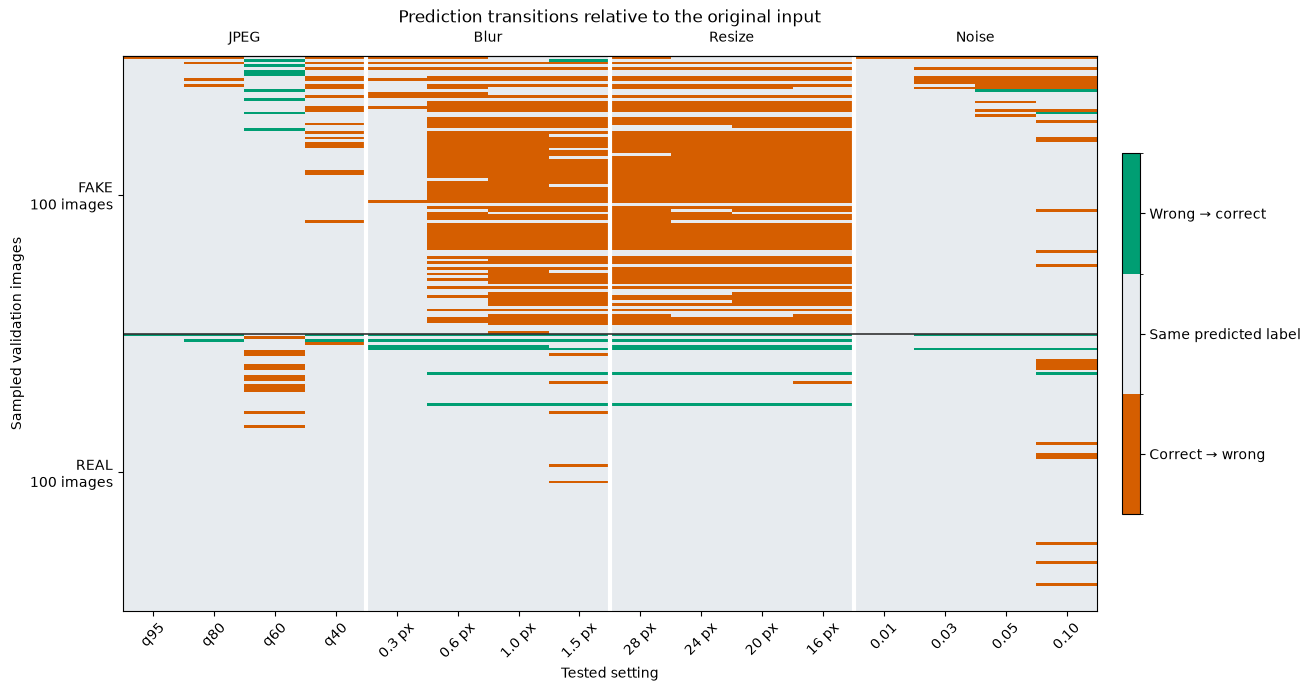

In [20]:
# Follow the same images across all edits.
from matplotlib.colors import ListedColormap, BoundaryNorm

transition_rng = np.random.default_rng(PROBE_SEED + 1)
transition_ids = []
for label in [0, 1]:
    ids = transition_rng.choice(
        np.flatnonzero(behavior_labels == label), 100, replace=False
    )
    ids = ids[np.argsort(np.abs(behavior_scores[0, ids] - 0.5), kind="stable")]
    transition_ids.extend(ids.tolist())
transition_ids = np.asarray(transition_ids)
all_correct = (behavior_scores > 0.5) == (behavior_labels == 0)[None, :]
changes = all_correct[1:, transition_ids].astype(np.int8) - all_correct[
    0, transition_ids
].astype(np.int8)
cmap = ListedColormap(["#D55E00", "#e7ebef", "#009E73"])
fig, ax = plt.subplots(figsize=(13, 6.8), layout="constrained")
heat = ax.imshow(
    changes.T,
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    norm=BoundaryNorm([-1.5, -0.5, 0.5, 1.5], 3),
)
for boundary in [3.5, 7.5, 11.5]:
    ax.axvline(boundary, color="white", lw=3)
ax.axhline(99.5, color="#333333", lw=1.2)
ax.set(
    xticks=np.arange(16),
    xticklabels=[c["label"] for c in behavior_conditions_list[1:]],
    yticks=[49.5, 149.5],
    yticklabels=["FAKE\n100 images", "REAL\n100 images"],
    xlabel="Tested setting",
    ylabel="Sampled validation images",
    title="Prediction transitions relative to the original input",
)
ax.tick_params(axis="x", labelrotation=45)
top = ax.secondary_xaxis("top")
top.set_xticks([1.5, 5.5, 9.5, 13.5], list(PROBE_FAMILIES))
top.tick_params(length=0, pad=8)
colorbar = fig.colorbar(heat, ax=ax, ticks=[-1, 0, 1], shrink=0.65, pad=0.025)
colorbar.ax.set_yticklabels(
    ["Correct → wrong", "Same predicted label", "Wrong → correct"]
)
finish_behavior_figure(fig, "prediction_transitions")


### 5.6 Try the changes yourself

The explorer below lets us inspect these behaviours one image at a time. Choose an image, select a modification, and move the strength slider from the original to one of the four tested settings. The two thumbnails will show the original and modified pixels side by side, while the score plot will show that image's P(FAKE) across all settings of the selected modification. The highlighted point follows the slider, and the dashed line marks the decision threshold. The preview set includes the sensitive gallery cases, examples with large score movements toward the correct label among initially incorrect predictions, and a few randomly selected images. It is designed for inspection rather than estimating how often a behaviour occurs. The preview images and measured scores are bundled in this notebook, so these controls work with a live kernel even without the full dataset; moving them does not train or reevaluate the model.


The explorer uses three controls and one plotting function. Its scores come from the same saved arrays as the figures above.


In [21]:
# Choose an image, an edit, and one of its four strengths (0 = original).
import ipywidgets as widgets
preview_choices = []
for index in behavior_arrays["preview_indices"]:
    label = "FAKE" if behavior_labels[index] == 0 else "REAL"
    preview_choices.append((f"{label} · {behavior_arrays['paths'][index]}", int(index)))
image_choice = widgets.Dropdown(options=preview_choices, description="Image:")
family_choice = widgets.Dropdown(options=list(PROBE_FAMILIES), description="Edit:")
strength_choice = widgets.IntSlider(min=0, max=4, value=2, description="Strength:", continuous_update=False)


In [22]:
# Redraw only the selected pair and its score curve when a control changes.
def show_edit(index, family, level):
    indices = behavior_groups[family]
    condition_index = indices[level]
    condition = behavior_conditions_list[condition_index]
    original = behavior_previews[index]
    changed = modify_behavior_image(original, condition["family"], condition["value"], index)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
    for ax, image, score_index, title in [
        (axes[0], original, 0, "Original"),
        (axes[1], changed, condition_index, condition["label"]),
    ]:
        score = behavior_scores[score_index, index]
        ax.imshow(image.transpose(1, 2, 0), interpolation="nearest")
        ax.set_title(f"{title} · P(FAKE) {score:.1%}")
        ax.axis("off")
    # Keep the entire curve visible, and mark the chosen strength.
    scores = behavior_scores[indices, index]
    axes[2].plot(range(5), scores, "o-")
    axes[2].scatter(level, scores[level], s=100, facecolors="none", edgecolors="black")
    axes[2].axhline(0.5, color="grey", ls="--")
    axes[2].set(xticks=range(5), xticklabels=["Original"] + PROBE_FAMILIES[family]["labels"],
                ylim=(-0.04, 1.04), ylabel="P(FAKE)", title=family)
    plt.show()
    plt.close(fig)


In [23]:
# Connect the controls to the plotting function. A live kernel is needed here.
explorer = widgets.interactive_output(show_edit, {
    "index": image_choice, "family": family_choice, "level": strength_choice,
})
display(widgets.VBox([image_choice, family_choice, strength_choice, explorer]))


### 5.7 What is worth investigating next?

The table below will bring a few measured settings back together so we can connect the image-level views with the full validation results. We'll compare overall accuracy, the fraction of fake images detected, false alarms on real images, and the fraction of all images whose predicted label changed from the original. The settings are examples from this exploratory sweep, not equally severe or optimized attacks. We can use these observations to choose image sequences, score trajectories, and before/after feature visualizations for the next part of the course. They describe how this fixed CNN responds under the specified processing choices; they do not establish why it learned that behaviour or how another model will respond.


In [24]:
# Summarize selected settings; the complete curves are above.
example_indices = [
    0,
    behavior_groups["JPEG"][3],
    behavior_groups["Blur"][2],
    behavior_groups["Resize"][1],
    behavior_groups["Noise"][4],
]
show_table(
    [
        "Input",
        "Accuracy",
        "FAKE detected",
        "REAL flagged FAKE",
        "Changed predicted label",
    ],
    [
        [
            (
                "Original"
                if i == 0
                else f"{behavior_conditions_list[i]['family']} · {behavior_conditions_list[i]['label']}"
            ),
            f"{behavior_stats['accuracy'][i]:.2%}",
            f"{behavior_stats['fake_detected'][i]:.2%}",
            f"{behavior_stats['real_false_alarm'][i]:.2%}",
            f"{behavior_stats['changed_label'][i]:.2%}",
        ]
        for i in example_indices
    ],
)
resize_i, blur_i, jpeg_i = (
    behavior_groups["Resize"][1],
    behavior_groups["Blur"][2],
    behavior_groups["JPEG"][3],
)
display(
    Markdown(
        f"With **32 → 28 → 32 resizing**, accuracy changes from **{behavior_stats['accuracy'][0]:.2%}** to "
        f"**{behavior_stats['accuracy'][resize_i]:.2%}**, and **{behavior_stats['changed_label'][resize_i]:.2%}** of images switch predicted labels. "
        f"At **0.6-pixel blur**, fake detection is **{behavior_stats['fake_detected'][blur_i]:.2%}**, while "
        f"**{behavior_stats['real_accepted'][blur_i]:.2%}** of real images are still accepted as real. "
        f"At **JPEG quality 60**, fake detection is **{behavior_stats['fake_detected'][jpeg_i]:.2%}**, but "
        f"**{behavior_stats['real_false_alarm'][jpeg_i]:.2%}** of real images are flagged as fake. "
        "These class-specific movements give us concrete cases to follow in the galleries, paired-score plots, and explorer."
    )
)


| Input | Accuracy | FAKE detected | REAL flagged FAKE | Changed predicted label |
| --- | --- | --- | --- | --- |
| Original | 94.54% | 94.60% | 5.52% | 0.00% |
| JPEG · q60 | 90.94% | 98.38% | 16.50% | 7.44% |
| Blur · 0.6 px | 66.79% | 33.78% | 0.20% | 33.09% |
| Resize · 28 px | 62.13% | 24.52% | 0.26% | 37.73% |
| Noise · 0.10 | 81.94% | 82.16% | 18.28% | 16.16% |

With **32 → 28 → 32 resizing**, accuracy changes from **94.54%** to **62.13%**, and **37.73%** of images switch predicted labels. At **0.6-pixel blur**, fake detection is **33.78%**, while **99.80%** of real images are still accepted as real. At **JPEG quality 60**, fake detection is **98.38%**, but **16.50%** of real images are flagged as fake. These class-specific movements give us concrete cases to follow in the galleries, paired-score plots, and explorer.

## 6. What the modification probe shows

The modification views answer part of that question. We kept each validation image and its label fixed, changed one property at a time, and followed the probability and predicted class. JPEG compression and moderate noise reduced accuracy, while even a small downsample-and-upsample operation caused a much larger change. Resizing from 32 to 28 pixels and back reduced the CNN's validation accuracy to **62.13%**; blur with radius 0.6 reduced it to **66.79%**. The score distributions and individual examples show why an average accuracy is not enough: we also need to see which class loses detections and whether many images move in the same direction. These are observations about the tested transformations, not proof that any particular image artifact is the cause.

The completed ResNet18 experiment gives us a second reference:

| Condition | Plain CNN accuracy | Fine-tuned ResNet18 accuracy |
| --- | ---: | ---: |
| Clean official test, 20,000 images | 94.290% | 97.735% |
| Original validation images | 94.54% | 97.92% |
| JPEG quality 60 | 90.94% | 96.24% |
| Gaussian blur, radius 0.6 | 66.79% | 63.69% |
| Resize 32 → 28 → 32 | 62.13% | 55.77% |
| Gaussian noise, standard deviation 0.05 | 89.83% | 90.68% |

Except for the explicitly marked official test row, these measurements use the same **10,000 validation images**, their original labels and the fixed 0.5 decision threshold.

ResNet18 is more accurate on clean images and at the listed JPEG and noise settings, but it performs worse than the small CNN at the listed blur and resize settings. A larger model with ImageNet pretraining therefore did not remove this sensitivity. This comparison changes several things together—architecture, initialization, input resizing and normalization—so it cannot isolate the effect of architecture alone. The table also shows selected settings from the full sweep; the complete curves are needed to see how behaviour changes with strength.

**Where Phase I continues.** `03_resnet18_behaviour.ipynb` shows the full ResNet18 curves next to these. `04_what_fools_the_detectors.ipynb` adds sharpening and colour edits (29 conditions) and shows that blur, resizing, JPEG and sharpening all move the output along one sharpness dial: sharpening real photos by 200 % raises the CNN's false alarms from 5.5 % to 83.7 %, and sharpening blurred fakes again brings detection back from 33.8 % to 88.6 %. It also breaks the errors down by object class, colour, image group and model agreement.
